## Daniel Barella

# Day 6: Pandas – Grouping, Aggregation & Sorting
## ✅ Learning Goals
1. Learn how to group and aggregate data.

2. Perform sorting and ranking operations.

3. Use value counts and unique functions.

4. Explore basic EDA (exploratory data analysis) on Titanic dataset.

### 🧑‍💻 Step 1: Grouping & Aggregation

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)

# Group by gender
gender_group = titanic.groupby('Sex')['Survived'].mean()
print(gender_group)

# Group by class
class_group = titanic.groupby('Pclass')['Survived'].mean()
print(class_group)

# Multiple groupby
multi_group = titanic.groupby(['Sex', 'Pclass'])['Survived'].mean()
print(multi_group)


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64
Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64


### 📌 Step 2: Aggregations

In [2]:
# Aggregate multiple stats at once
agg_stats = titanic.groupby('Pclass')['Age'].agg(['mean', 'median', 'count'])
print(agg_stats)


             mean  median  count
Pclass                          
1       38.233441    37.0    186
2       29.877630    29.0    173
3       25.140620    24.0    355


### 📌 Step 3: Sorting

In [4]:
# Sort by age
titanic.sort_values(by='Age').head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,NaN,C
755,756,1,2,"Hamalainen, Master. Viljo",male,0.67,1,1,250649,14.5000,NaN,S
644,645,1,3,"Baclini, Miss. Eugenie",female,0.75,2,1,2666,19.2583,NaN,C
469,470,1,3,"Baclini, Miss. Helene Barbara",female,0.75,2,1,2666,19.2583,NaN,C
78,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,NaN,S
831,832,1,2,"Richards, Master. George Sibley",male,0.83,1,1,29106,18.7500,NaN,S
305,306,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S
827,828,1,2,"Mallet, Master. Andre",male,1.00,0,2,S.C./PARIS 2079,37.0042,NaN,C
381,382,1,3,"Nakid, Miss. Maria (""Mary"")",female,1.00,0,2,2653,15.7417,NaN,C
164,165,0,3,"Panula, Master. Eino Viljami",male,1.00,4,1,3101295,39.6875,NaN,S


In [5]:
# Sort by fare (descending)
titanic.sort_values(by='Fare', ascending=False).head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
88,89,1,1,"Fortune, Miss. Mabel Helen",female,23.0,3,2,19950,263.0000,C23 C25 C27,S
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
341,342,1,1,"Fortune, Miss. Alice Elizabeth",female,24.0,3,2,19950,263.0000,C23 C25 C27,S
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
311,312,1,1,"Ryerson, Miss. Emily Borie",female,18.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
742,743,1,1,"Ryerson, Miss. Susan Parker ""Suzette""",female,21.0,2,2,PC 17608,262.3750,B57 B59 B63 B66,C
118,119,0,1,"Baxter, Mr. Quigg Edmond",male,24.0,0,1,PC 17558,247.5208,B58 B60,C


### 📌 Step 4: Value Counts & Unique

In [6]:
# Count how many from each class
print(titanic['Pclass'].value_counts())

# Unique embarkation ports
print(titanic['Embarked'].unique())


3    491
1    216
2    184
Name: Pclass, dtype: int64
['S' 'C' 'Q' nan]


### 📌 Step 5: Mini Project

⚓ Titanic Deep Dive – Who Had the Advantage?

1. Compare survival rates by passenger class (Pclass).

2. Compare survival rates by Embarked port.

3. Find highest paying passenger and check if they survived.

4. Find family survival patterns (SibSp + Parch).

### 1. Compare survival rates by passenger class (Pclass).

In [7]:
# Survival rate by Pclass
survival_by_class = titanic.groupby("Pclass")["Survived"].mean() * 100

print("Survival rates by passenger class:")
print(survival_by_class)

Survival rates by passenger class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


### 2. Compare survival rates by Embarked port.

In [9]:
# Survival rate by Embarked port.
survival_by_port= titanic.groupby("Embarked")["Survived"].mean() * 100

print("Survival rates by Embarked port:")
print(survival_by_port)

Survival rates by Embarked port:
Embarked
C    55.357143
Q    38.961039
S    33.695652
Name: Survived, dtype: float64


### 3. Find highest paying passenger and check if they survived.

In [10]:
# Find passenger with highest fare
highest_fare_passenger = titanic.loc[titanic["Fare"].idxmax()]

print("Highest Fare Passenger:")
print(highest_fare_passenger[["Name", "Pclass", "Fare", "Survived"]])

Highest Fare Passenger:
Name        Ward, Miss. Anna
Pclass                     1
Fare                512.3292
Survived                   1
Name: 258, dtype: object


### 4. Find family survival patterns (SibSp + Parch).

In [11]:
# Create a column for family size
titanic['FamilySize'] = titanic['SibSp'] + titanic['Parch']

# Group by family size and calculate survival rates
family_survival = titanic.groupby('FamilySize')['Survived'].mean().reset_index()

print(family_survival)


   FamilySize  Survived
0           0  0.303538
1           1  0.552795
2           2  0.578431
3           3  0.724138
4           4  0.200000
5           5  0.136364
6           6  0.333333
7           7  0.000000
8          10  0.000000


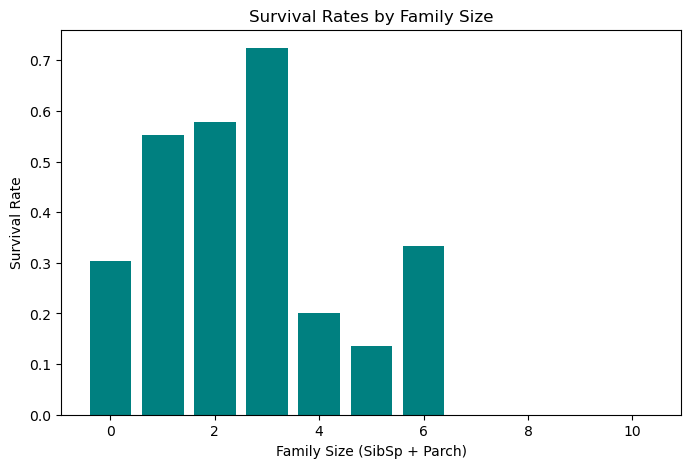

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(family_survival['FamilySize'], family_survival['Survived'], color='teal')
plt.xlabel("Family Size (SibSp + Parch)")
plt.ylabel("Survival Rate")
plt.title("Survival Rates by Family Size")
plt.show()
